In [20]:
# Configuration initiale de l'environnement : définition des graines aléatoires (seed) pour assurer la reproductibilité, et vérification de la disponibilité du GPU.
import os
import random
import numpy as np
import tensorflow as tf

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow :", tf.__version__)
print("GPU disponible :", tf.config.list_physical_devices("GPU"))

assert len(tf.config.list_physical_devices("GPU")) > 0, \
    "Aucun GPU détecté. Active le GPU dans les paramètres Colab."

print("\nEnvironnement prêt.")

TensorFlow : 2.21.0
GPU disponible : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

Environnement prêt.


In [21]:
# Installation et importation des bibliothèques nécessaires au projet (KaggleHub, Scikit-learn, Pandas, Matplotlib, etc.).
!pip install -q kagglehub scikit-learn pandas matplotlib seaborn Pillow pyyaml

import kagglehub
import sklearn
import pandas as pd
import matplotlib

print("KaggleHub :", kagglehub.__version__)
print("Scikit-learn :", sklearn.__version__)
print("Pandas :", pd.__version__)
print("Matplotlib :", matplotlib.__version__)

KaggleHub : 1.0.3
Scikit-learn : 1.6.1
Pandas : 2.2.3
Matplotlib : 3.10.0


In [22]:
# Téléchargement automatique de la base de données PlantVillage depuis Kaggle à l'aide de kagglehub et affichage du contenu racine.
import kagglehub
from pathlib import Path

print("Téléchargement de PlantVillage...")

dataset_path = kagglehub.dataset_download(
    "emmarex/plantdisease"
)

dataset_path = Path(dataset_path)

print("\nTéléchargement terminé.")
print("Chemin :", dataset_path)
print("\nContenu :")

for item in sorted(dataset_path.iterdir()):
    print(item.name)

Téléchargement de PlantVillage...
Using Colab cache for faster access to the 'plantdisease' dataset.

Téléchargement terminé.
Chemin : /kaggle/input/plantdisease

Contenu :
PlantVillage
plantvillage


In [23]:
# Clonage du dépôt GitHub du projet pour récupérer les fichiers de répartition (.csv) et vérification de leur existence locale.
import subprocess
from pathlib import Path

PROJECT_DIR = Path("/content/Intelligent-recognition-of-plant-diseases")

if not PROJECT_DIR.exists():
    subprocess.run(
        [
            "git", "clone", "--depth", "1",
            "https://github.com/4ymanee/Intelligent-recognition-of-plant-diseases.git",
            str(PROJECT_DIR)
        ],
        check=True
    )

PARTITION_DIR = PROJECT_DIR / "partitions" / "pv"

print("Projet :", PROJECT_DIR)
print("Partitions :", PARTITION_DIR)

for filename in ["train.csv", "val.csv", "test.csv", "partition.csv"]:
    path = PARTITION_DIR / filename
    assert path.exists(), f"Fichier manquant : {filename}"
    print(filename, "OK")

Projet : /content/Intelligent-recognition-of-plant-diseases
Partitions : /content/Intelligent-recognition-of-plant-diseases/partitions/pv
train.csv OK
val.csv OK
test.csv OK
partition.csv OK


In [24]:
# Chargement des fichiers CSV de partitionnement avec Pandas et analyse de la distribution des classes dans les jeux d'entraînement, de validation et de test.
import pandas as pd

train_df = pd.read_csv(PARTITION_DIR / "train.csv")
val_df = pd.read_csv(PARTITION_DIR / "val.csv")
test_df = pd.read_csv(PARTITION_DIR / "test.csv")
partition_df = pd.read_csv(PARTITION_DIR / "partition.csv")

print("Dimensions :")
print("Train      :", train_df.shape)
print("Validation :", val_df.shape)
print("Test       :", test_df.shape)
print("Partition  :", partition_df.shape)

print("\nColonnes train :", train_df.columns.tolist())

print("\nRépartition des classes :")
print(
    pd.concat([
        train_df.assign(partition="train"),
        val_df.assign(partition="validation"),
        test_df.assign(partition="test")
    ])
    .groupby(["partition", "label"])
    .size()
    .unstack(fill_value=0)
)

print("\nClasses :", sorted(train_df["label"].unique()))

Dimensions :
Train      : (3418, 2)
Validation : (732, 2)
Test       : (720, 2)
Partition  : (4870, 9)

Colonnes train : ['relpath', 'label']

Répartition des classes :
label       alternariose_precoce  cladosporiose  mildiou_tardif  saine  \
partition                                                                
test                         148            140             136    148   
train                        703            668             644    703   
validation                   148            144             140    148   

label       septoriose  
partition               
test               148  
train              700  
validation         152  

Classes : ['alternariose_precoce', 'cladosporiose', 'mildiou_tardif', 'saine', 'septoriose']


In [25]:
# Recherche et localisation du premier fichier image d'exemple dans les répertoires physiques du dataset téléchargé pour tester la correspondance.
from pathlib import Path

sample_relpath = train_df.iloc[0]["relpath"]

print("Chemin relatif du manifeste :", sample_relpath)

# Recherche exacte du chemin relatif dans le dataset
candidates = []

for p in dataset_path.rglob("*"):
    if p.is_file() and p.as_posix().endswith("/" + sample_relpath):
        candidates.append(p)

print("\nNombre de correspondances exactes :", len(candidates))

for p in candidates:
    print(p)

Chemin relatif du manifeste : Tomato___Early_blight/0012b9d2-2130-4a06-a834-b1f3af34f57e___RS_Erly.B 8389.JPG

Nombre de correspondances exactes : 0


In [26]:
# Recherche globale d'un fichier image par son nom brut pour identifier d'éventuels écarts de nommage ou d'organisation des dossiers.
from pathlib import Path

sample_relpath = train_df.iloc[0]["relpath"]
sample_filename = Path(sample_relpath).name

print("Fichier recherché :", sample_filename)

matches = [
    p for p in dataset_path.rglob("*")
    if p.is_file() and p.name == sample_filename
]

print("\nNombre de correspondances :", len(matches))

for i, p in enumerate(matches, 1):
    print(f"\nCorrespondance {i}")
    print("Chemin complet :", p)
    print("Dossier parent :", p.parent)
    print("Nom du dossier parent :", p.parent.name)

Fichier recherché : 0012b9d2-2130-4a06-a834-b1f3af34f57e___RS_Erly.B 8389.JPG

Nombre de correspondances : 2

Correspondance 1
Chemin complet : /kaggle/input/plantdisease/plantvillage/PlantVillage/Tomato_Early_blight/0012b9d2-2130-4a06-a834-b1f3af34f57e___RS_Erly.B 8389.JPG
Dossier parent : /kaggle/input/plantdisease/plantvillage/PlantVillage/Tomato_Early_blight
Nom du dossier parent : Tomato_Early_blight

Correspondance 2
Chemin complet : /kaggle/input/plantdisease/PlantVillage/Tomato_Early_blight/0012b9d2-2130-4a06-a834-b1f3af34f57e___RS_Erly.B 8389.JPG
Dossier parent : /kaggle/input/plantdisease/PlantVillage/Tomato_Early_blight
Nom du dossier parent : Tomato_Early_blight


In [27]:
# Exploration structurelle du dataset téléchargé en listant les dossiers principaux et sous-dossiers de classes pour valider l'arborescence.
print("CONTENU DES DOSSIERS PRINCIPAUX")

for folder in sorted(dataset_path.iterdir()):
    if folder.is_dir():
        print(f"\nDossier : {folder}")

        subfolders = [
            p for p in folder.iterdir()
            if p.is_dir()
        ]

        for subfolder in sorted(subfolders)[:15]:
            print("  -", subfolder.name)

            classes = [
                p.name for p in subfolder.iterdir()
                if p.is_dir()
            ]

            for class_name in classes[:8]:
                print("      *", class_name)

CONTENU DES DOSSIERS PRINCIPAUX

Dossier : /kaggle/input/plantdisease/PlantVillage
  - Pepper__bell___Bacterial_spot
  - Pepper__bell___healthy
  - Potato___Early_blight
  - Potato___Late_blight
  - Potato___healthy
  - Tomato_Bacterial_spot
  - Tomato_Early_blight
  - Tomato_Late_blight
  - Tomato_Leaf_Mold
  - Tomato_Septoria_leaf_spot
  - Tomato_Spider_mites_Two_spotted_spider_mite
  - Tomato__Target_Spot
  - Tomato__Tomato_YellowLeaf__Curl_Virus
  - Tomato__Tomato_mosaic_virus
  - Tomato_healthy

Dossier : /kaggle/input/plantdisease/plantvillage
  - PlantVillage
      * Pepper__bell___Bacterial_spot
      * Potato___healthy
      * Tomato_Leaf_Mold
      * Tomato__Tomato_YellowLeaf__Curl_Virus
      * Tomato_Bacterial_spot
      * Tomato_Septoria_leaf_spot
      * Tomato_healthy
      * Tomato_Spider_mites_Two_spotted_spider_mite


In [28]:
# Recherche ciblée des dossiers de maladie (comme 'Early blight') dans le dataset téléchargé pour analyser les différences d'écriture (ex: underscores vs triple underscores).
print("Classe attendue dans le manifeste :")
print(Path(sample_relpath).parts[0])

print("\nClasses contenant éventuellement Early blight :")

for p in dataset_path.rglob("*"):
    if p.is_dir() and "early" in p.name.lower():
        print(p)

Classe attendue dans le manifeste :
Tomato___Early_blight

Classes contenant éventuellement Early blight :
/kaggle/input/plantdisease/PlantVillage/Tomato_Early_blight
/kaggle/input/plantdisease/PlantVillage/Potato___Early_blight
/kaggle/input/plantdisease/plantvillage/PlantVillage/Tomato_Early_blight
/kaggle/input/plantdisease/plantvillage/PlantVillage/Potato___Early_blight


In [29]:
# Comptage et affichage d'exemples d'images dans les répertoires physiques du dataset pour vérifier l'intégrité et le format des fichiers.
from collections import Counter

image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}

for folder in sorted(dataset_path.iterdir()):
    if not folder.is_dir():
        continue

    images = [
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in image_extensions
    ]

    print("\nDossier :", folder)
    print("Nombre d'images :", len(images))
    print("Exemples :")

    for p in images[:5]:
        print(" ", p.relative_to(dataset_path))


Dossier : /kaggle/input/plantdisease/PlantVillage
Nombre d'images : 20638
Exemples :
  PlantVillage/Pepper__bell___Bacterial_spot/0f72db9c-d635-4415-9781-68937328aed2___NREC_B.Spot 9188.JPG
  PlantVillage/Pepper__bell___Bacterial_spot/1b8d3e98-43d9-441d-93ef-a359e6e9ddc2___NREC_B.Spot 9052.JPG
  PlantVillage/Pepper__bell___Bacterial_spot/b6d35d21-4812-4e32-ab9a-b6ddda8cbb79___JR_B.Spot 8972.JPG
  PlantVillage/Pepper__bell___Bacterial_spot/e4e7e5a2-5aa1-4378-833d-9142358c7c9b___JR_B.Spot 9092.JPG
  PlantVillage/Pepper__bell___Bacterial_spot/8b50f2db-cbf2-4758-bea6-a011f0cc1497___JR_B.Spot 3235.JPG

Dossier : /kaggle/input/plantdisease/plantvillage
Nombre d'images : 20638
Exemples :
  plantvillage/PlantVillage/Pepper__bell___Bacterial_spot/0f72db9c-d635-4415-9781-68937328aed2___NREC_B.Spot 9188.JPG
  plantvillage/PlantVillage/Pepper__bell___Bacterial_spot/1b8d3e98-43d9-441d-93ef-a359e6e9ddc2___NREC_B.Spot 9052.JPG
  plantvillage/PlantVillage/Pepper__bell___Bacterial_spot/b6d35d21-4812-4

In [30]:
# Résolution des chemins réels des images : indexation de l'arborescence de PlantVillage par nom de fichier et réassociation avec les chemins relatifs du manifeste.
from pathlib import Path
from collections import defaultdict
import pandas as pd

# Une seule copie de PlantVillage
IMAGE_ROOT = dataset_path / "PlantVillage"

assert IMAGE_ROOT.exists(), f"Dossier introuvable : {IMAGE_ROOT}"

print("Racine sélectionnée :", IMAGE_ROOT)

# Indexation des images par nom de fichier
image_index = defaultdict(list)

extensions = {".jpg", ".jpeg", ".png", ".bmp"}

for path in IMAGE_ROOT.rglob("*"):
    if path.is_file() and path.suffix.lower() in extensions:
        image_index[path.name].append(path)

print("Nombre d'images indexées :", sum(len(v) for v in image_index.values()))
print("Nombre de noms de fichiers distincts :", len(image_index))

# Réunir les trois manifestes sans modifier leurs contenus
all_df = pd.concat([
    train_df.assign(partition="train"),
    val_df.assign(partition="validation"),
    test_df.assign(partition="test")
], ignore_index=True)

# Retrouver chaque fichier
resolved_paths = []
missing_files = []
ambiguous_files = []

for relpath in all_df["relpath"]:
    filename = Path(relpath).name
    matches = image_index.get(filename, [])

    if len(matches) == 0:
        missing_files.append(relpath)
        resolved_paths.append(None)
    elif len(matches) > 1:
        ambiguous_files.append((relpath, matches))
        resolved_paths.append(None)
    else:
        resolved_paths.append(str(matches[0]))

all_df["actual_path"] = resolved_paths

print("\n--- BILAN ---")
print("Images attendues :", len(all_df))
print("Images retrouvées :", all_df["actual_path"].notna().sum())
print("Images manquantes :", len(missing_files))
print("Fichiers ambigus dans la copie sélectionnée :", len(ambiguous_files))

if missing_files:
    print("\nExemples manquants :", missing_files[:5])

if ambiguous_files:
    print("\nExemples ambigus :", ambiguous_files[:3])

# Examiner la correspondance label / dossier réel
if not missing_files and not ambiguous_files:
    all_df["actual_folder"] = all_df["actual_path"].apply(
        lambda p: Path(p).parent.name
    )

    print("\n--- CORRESPONDANCE DES CLASSES ---")
    mapping = (
        all_df.groupby(["label", "actual_folder"])
        .size()
        .reset_index(name="nombre_images")
    )
    display(mapping)

    print("\n--- DISTRIBUTION PAR PARTITION ---")
    display(
        all_df.groupby(["partition", "label"])
        .size()
        .unstack(fill_value=0)
    )

    # Chaque label doit correspondre à un seul dossier réel
    folders_per_label = all_df.groupby("label")["actual_folder"].nunique()
    labels_per_folder = all_df.groupby("actual_folder")["label"].nunique()

    print("\nNombre de dossiers par label :")
    print(folders_per_label)

    print("\nNombre de labels par dossier :")
    print(labels_per_folder)

    assert (folders_per_label == 1).all(), \
        "Un label correspond à plusieurs dossiers réels."

    assert (labels_per_folder == 1).all(), \
        "Un dossier réel correspond à plusieurs labels."

    print("\nVérification des chemins terminée.")

Racine sélectionnée : /kaggle/input/plantdisease/PlantVillage
Nombre d'images indexées : 20638
Nombre de noms de fichiers distincts : 20638

--- BILAN ---
Images attendues : 4870
Images retrouvées : 4870
Images manquantes : 0
Fichiers ambigus dans la copie sélectionnée : 0

--- CORRESPONDANCE DES CLASSES ---


,label,actual_folder,nombre_images
0,alternariose_precoce,Tomato_Early_blight,999
1,cladosporiose,Tomato_Leaf_Mold,952
2,mildiou_tardif,Tomato_Late_blight,920
3,saine,Tomato_healthy,999
4,septoriose,Tomato_Septoria_leaf_spot,1000



--- DISTRIBUTION PAR PARTITION ---


label,alternariose_precoce,cladosporiose,mildiou_tardif,saine,septoriose
partition,,,,,
test,148,140,136,148,148
train,703,668,644,703,700
validation,148,144,140,148,152



Nombre de dossiers par label :
label
alternariose_precoce    1
cladosporiose           1
mildiou_tardif          1
saine                   1
septoriose              1
Name: actual_folder, dtype: int64

Nombre de labels par dossier :
actual_folder
Tomato_Early_blight          1
Tomato_Late_blight           1
Tomato_Leaf_Mold             1
Tomato_Septoria_leaf_spot    1
Tomato_healthy               1
Name: label, dtype: int64

Vérification des chemins terminée.


In [31]:
# Définition du dictionnaire de correspondance (mapping) entre les noms de classe et leurs indices numériques, puis encodage des labels dans le DataFrame.
CLASS_NAMES = [
    "alternariose_precoce",
    "cladosporiose",
    "mildiou_tardif",
    "saine",
    "septoriose"
]

NUM_CLASSES = len(CLASS_NAMES)

class_to_idx = {
    name: idx for idx, name in enumerate(CLASS_NAMES)
}

idx_to_class = {
    idx: name for name, idx in class_to_idx.items()
}

print("Mapping des classes :")
for idx, name in idx_to_class.items():
    print(f"{idx} -> {name}")

# Vérifier que les cinq classes sont présentes
assert set(all_df["label"].unique()) == set(CLASS_NAMES)

# Ajouter l'identifiant numérique à chaque image
all_df = all_df.copy()
all_df["label_id"] = all_df["label"].map(class_to_idx)

assert all_df["label_id"].notna().all()

print("\nNombre de classes :", NUM_CLASSES)
print("Nombre total d'images :", len(all_df))

Mapping des classes :
0 -> alternariose_precoce
1 -> cladosporiose
2 -> mildiou_tardif
3 -> saine
4 -> septoriose

Nombre de classes : 5
Nombre total d'images : 4870


In [32]:
# Séparation finale des données nettoyées et mappées en sous-ensembles Train, Validation et Test, avec vérification stricte du nombre d'images attendues.
train_data = all_df[all_df["partition"] == "train"].copy()
val_data = all_df[all_df["partition"] == "validation"].copy()
test_data = all_df[all_df["partition"] == "test"].copy()

print("Train      :", len(train_data))
print("Validation :", len(val_data))
print("Test       :", len(test_data))

assert len(train_data) == 3418
assert len(val_data) == 732
assert len(test_data) == 720

Train      : 3418
Validation : 732
Test       : 720


In [33]:
# Définition de la fonction de chargement et de prétraitement individuel des images TensorFlow (lecture, décodage, normalisation et redimensionnement à 224x224).
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def load_image(image_path, label):
    image = tf.io.read_file(image_path)

    image = tf.io.decode_jpeg(
        image,
        channels=3
    )

    image = tf.image.convert_image_dtype(
        image,
        tf.float32
    )

    image = tf.image.resize(
        image,
        IMG_SIZE,
        antialias=True
    )

    image = tf.ensure_shape(
        image,
        (224, 224, 3)
    )

    label = tf.cast(label, tf.int32)

    return image, label

In [34]:
# Création et configuration optimisée des objets tf.data.Dataset (mélange, mapping en parallèle, batching et prefetch) pour l'entraînement, la validation et le test.
def create_dataset(dataframe, training=False):
    paths = dataframe["actual_path"].astype(str).values
    labels = dataframe["label_id"].astype("int32").values

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTOTUNE,
        deterministic=True
    )

    dataset = dataset.batch(
        BATCH_SIZE,
        drop_remainder=False
    )

    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


train_ds = create_dataset(train_data, training=True)
val_ds = create_dataset(val_data, training=False)
test_ds = create_dataset(test_data, training=False)

print("Datasets TensorFlow créés.")

Datasets TensorFlow créés.


In [35]:
# Validation technique du pipeline d'entrée en extrayant un premier batch et en vérifiant ses types, dimensions, valeurs minimales/maximales et labels.
import numpy as np

images, labels = next(iter(train_ds))

print("Dimensions du batch :", images.shape)
print("Type des images :", images.dtype)
print("Type des labels :", labels.dtype)

print("Valeur minimale :", float(tf.reduce_min(images)))
print("Valeur maximale :", float(tf.reduce_max(images)))

print("Labels du batch :", labels.numpy())

assert images.shape[1:] == (224, 224, 3)
assert images.dtype == tf.float32
assert labels.dtype == tf.int32

assert np.isfinite(images.numpy()).all()
assert float(tf.reduce_min(images)) >= 0.0
assert float(tf.reduce_max(images)) <= 1.0

assert int(tf.reduce_min(labels)) >= 0
assert int(tf.reduce_max(labels)) < NUM_CLASSES

print("\nBatch validé.")

Dimensions du batch : (32, 224, 224, 3)
Type des images : <dtype: 'float32'>
Type des labels : <dtype: 'int32'>
Valeur minimale : 0.0
Valeur maximale : 0.9817357063293457
Labels du batch : [3 2 2 3 2 3 3 4 1 2 3 4 3 0 4 0 3 0 4 4 4 0 1 2 4 0 3 1 3 0 0 2]

Batch validé.


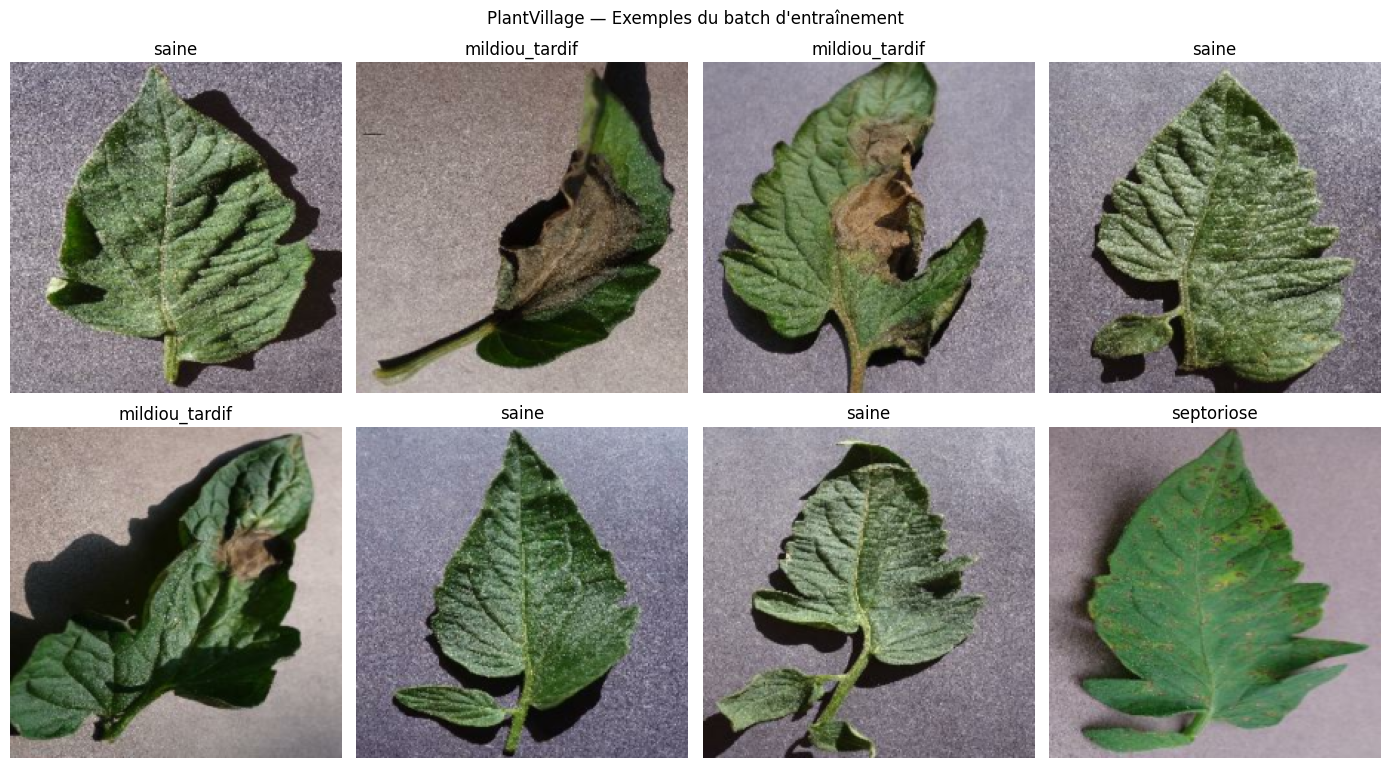

In [36]:
# Visualisation d'un échantillon d'images du premier batch d'entraînement avec Matplotlib pour s'assurer visuellement du bon chargement et du mapping des étiquettes.
import matplotlib.pyplot as plt

images_np = images.numpy()
labels_np = labels.numpy()

plt.figure(figsize=(14, 8))

for i in range(min(8, len(images_np))):
    plt.subplot(2, 4, i + 1)

    plt.imshow(images_np[i])
    plt.title(idx_to_class[int(labels_np[i])])
    plt.axis("off")

plt.suptitle("PlantVillage — Exemples du batch d'entraînement")
plt.tight_layout()
plt.show()

In [37]:
# Construction d'un modèle CNN compact à trois blocs convolutifs pour la classification des cinq maladies des feuilles de tomate.

def build_e0_model():

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(224, 224, 3)),

        tf.keras.layers.Conv2D(32, (3, 3), padding="same"),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Activation("relu"),
        tf.keras.layers.MaxPooling2D((2, 2)),

        tf.keras.layers.Conv2D(64, (3, 3), padding="same"),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Activation("relu"),
        tf.keras.layers.MaxPooling2D((2, 2)),

        tf.keras.layers.Conv2D(128, (3, 3), padding="same"),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Activation("relu"),
        tf.keras.layers.MaxPooling2D((2, 2)),

        tf.keras.layers.GlobalAveragePooling2D(),
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")
    ])

    return model


model = build_e0_model()

In [38]:
# Compilation du modèle avec Adam et Sparse Categorical Crossentropy, puis affichage de son architecture et de ses paramètres.

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,301 (434.77 KB)

 Trainable params: 110,853 (433.02 KB)

 Non-trainable params: 448 (1.75 KB)

In [39]:
# Extraction d'un batch fixe de 32 images d'entraînement pour vérifier la capacité d'apprentissage du CNN.

small_batch = train_ds.unbatch().take(32).batch(32).repeat()

In [40]:
# Entraînement d'un modèle temporaire sur le même petit batch pendant 30 époques afin de vérifier sa capacité à surapprendre.

sanity_model = build_e0_model()

sanity_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

overfit_history = sanity_model.fit(
    small_batch,
    steps_per_epoch=1,
    epochs=30,
    verbose=1
)

Epoch 1/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 16s 16s/step - accuracy: 0.0625 - loss: 1.7823
Epoch 2/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step - accuracy: 0.4062 - loss: 1.4825
Epoch 3/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 161ms/step - accuracy: 0.5312 - loss: 1.2884
Epoch 4/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 171ms/step - accuracy: 0.6250 - loss: 1.0677
Epoch 5/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 173ms/step - accuracy: 0.5000 - loss: 1.2060
Epoch 6/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 166ms/step - accuracy: 0.5625 - loss: 1.0273
Epoch 7/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 168ms/step - accuracy: 0.5000 - loss: 1.1832
Epoch 8/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 190ms/step - accuracy: 0.5938 - loss: 0.9016
Epoch 9/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 182ms/step - accuracy: 0.6562 - loss: 0.9955
Epoch 10/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 162ms/step - accuracy: 0.6562 - loss: 0.9920
Epoch 11/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 185ms/step - accuracy: 0.6562 - loss: 0.8935
Epoch 12/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 170ms/step - accuracy: 0.7188 - loss

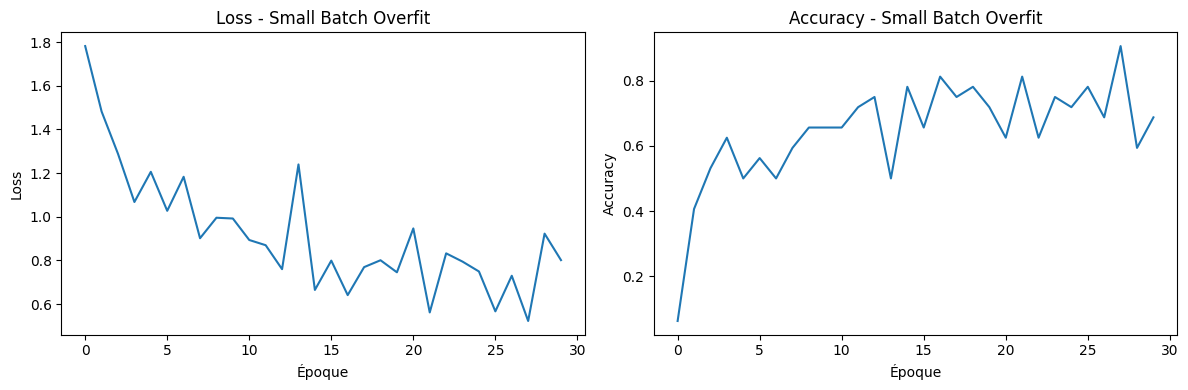

In [41]:
# Visualisation de l'évolution de la loss et de l'accuracy pendant le test de surapprentissage.

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(overfit_history.history["loss"])
plt.title("Loss - Small Batch Overfit")
plt.xlabel("Époque")
plt.ylabel("Loss")

plt.subplot(1, 2, 2)
plt.plot(overfit_history.history["accuracy"])
plt.title("Accuracy - Small Batch Overfit")
plt.xlabel("Époque")
plt.ylabel("Accuracy")

plt.tight_layout()
plt.show()

In [42]:
# Création du dossier destiné à sauvegarder le meilleur modèle et les résultats de l'entraînement E0.

import os

OUTPUT_DIR = "/content/e0_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Dossier de sauvegarde :", OUTPUT_DIR)

Dossier de sauvegarde : /content/e0_results


In [43]:
# Calcul du Macro-F1 après chaque époque et sauvegarde des poids correspondant à la meilleure performance de validation.

from sklearn.metrics import f1_score
import numpy as np

class MacroF1Callback(tf.keras.callbacks.Callback):

    def __init__(self, validation_data, patience=8):
        super().__init__()
        self.validation_data = validation_data
        self.patience = patience
        self.best_f1 = -1
        self.wait = 0
        self.best_weights = None

    def on_epoch_end(self, epoch, logs=None):

        y_true = np.concatenate([
            labels.numpy() for _, labels in self.validation_data
        ])

        y_prob = self.model.predict(self.validation_data, verbose=0)
        y_pred = np.argmax(y_prob, axis=1)

        val_f1 = f1_score(y_true, y_pred, average="macro")

        logs["val_macro_f1"] = val_f1

        print(f" — val_macro_f1: {val_f1:.4f}")

        if val_f1 > self.best_f1:
            self.best_f1 = val_f1
            self.best_weights = self.model.get_weights()
            self.wait = 0

            self.model.save_weights(
                os.path.join(OUTPUT_DIR, "best_e0.weights.h5")
            )

        else:
            self.wait += 1

            if self.wait >= self.patience:
                print("\nArrêt anticipé : le Macro-F1 ne s'améliore plus.")
                self.model.stop_training = True

    def on_train_end(self, logs=None):
        if self.best_weights is not None:
            self.model.set_weights(self.best_weights)
            print(f"Meilleur Macro-F1 validation : {self.best_f1:.4f}")

In [44]:
# Initialisation et compilation du modèle CNN E0 destiné à l'entraînement complet.

model = build_e0_model()

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_8 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,301 (434.77 KB)

 Trainable params: 110,853 (433.02 KB)

 Non-trainable params: 448 (1.75 KB)

In [45]:
# Entraînement du CNN sur les données train avec suivi du Macro-F1 sur les données de validation et sauvegarde du meilleur modèle.

macro_f1_callback = MacroF1Callback(
    validation_data=val_ds,
    patience=8
)

csv_logger = tf.keras.callbacks.CSVLogger(
    os.path.join(OUTPUT_DIR, "training_log.csv")
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    callbacks=[
        macro_f1_callback,
        csv_logger
    ],
    verbose=1
)

Epoch 1/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 266ms/step - accuracy: 0.6476 - loss: 0.9199 — val_macro_f1: 0.0673
107/107 ━━━━━━━━━━━━━━━━━━━━ 50s 415ms/step - accuracy: 0.7452 - loss: 0.6857 - val_accuracy: 0.2022 - val_loss: 3.3744 - val_macro_f1: 0.0673
Epoch 2/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - accuracy: 0.8432 - loss: 0.4467 — val_macro_f1: 0.0673
107/107 ━━━━━━━━━━━━━━━━━━━━ 53s 179ms/step - accuracy: 0.8464 - loss: 0.4202 - val_accuracy: 0.2022 - val_loss: 6.8529 - val_macro_f1: 0.0673
Epoch 3/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step - accuracy: 0.8723 - loss: 0.3577 — val_macro_f1: 0.0673
107/107 ━━━━━━━━━━━━━━━━━━━━ 22s 205ms/step - accuracy: 0.8833 - loss: 0.3309 - val_accuracy: 0.2022 - val_loss: 7.3090 - val_macro_f1: 0.0673
Epoch 4/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - accuracy: 0.8974 - loss: 0.2909 — val_macro_f1: 0.3034
107/107 ━━━━━━━━━━━━━━━━━━━━ 19s 180ms/step - accuracy: 0.8929 - loss: 0.2953 - val_accuracy: 0.4003 - val_loss: 2.9059 - val_m

In [46]:
# Sauvegarde du modèle E0 sélectionné selon le meilleur Macro-F1 obtenu sur la validation.

MODEL_PATH = os.path.join(OUTPUT_DIR, "best_e0_model.keras")

model.save(MODEL_PATH)

print("Modèle sauvegardé :", MODEL_PATH)
print("Meilleur Macro-F1 :", macro_f1_callback.best_f1)

Modèle sauvegardé : /content/e0_results/best_e0_model.keras
Meilleur Macro-F1 : 0.9484819741149414


In [47]:
# Enregistrement des paramètres expérimentaux et du mapping des classes pour assurer la reproductibilité de E0.

import json

config = {
    "experiment": "E0",
    "architecture": "CNN_3_blocks",
    "image_size": [224, 224],
    "batch_size": BATCH_SIZE,
    "learning_rate": 0.001,
    "optimizer": "Adam",
    "epochs_max": 50,
    "epochs_completed": len(history.history["loss"]),
    "seed": SEED,
    "classes": CLASS_NAMES,
    "best_validation_macro_f1": float(macro_f1_callback.best_f1),
    "dataset": "PlantVillage",
    "augmentation": False
}

with open(os.path.join(OUTPUT_DIR, "e0_config.json"), "w") as f:
    json.dump(config, f, indent=4)

print("Configuration sauvegardée.")

Configuration sauvegardée.


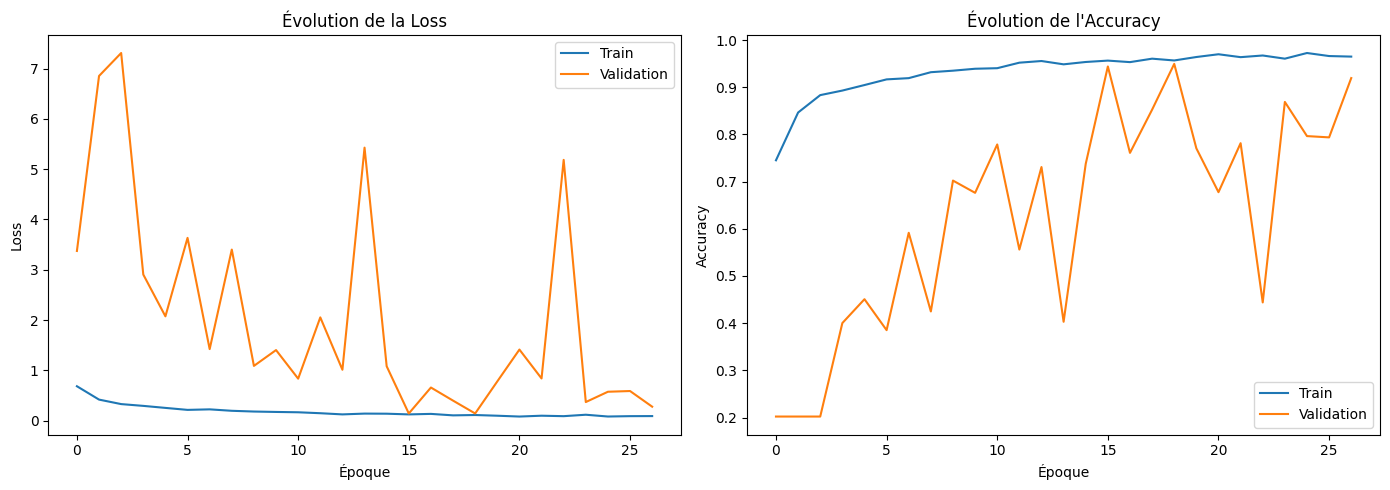

In [48]:
# Visualisation des courbes de loss et d'accuracy sur les ensembles d'entraînement et de validation.

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Train")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Évolution de la Loss")
plt.xlabel("Époque")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Train")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Évolution de l'Accuracy")
plt.xlabel("Époque")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

Colonnes disponibles : ['epoch', 'accuracy', 'loss', 'val_accuracy', 'val_loss', 'val_macro_f1']


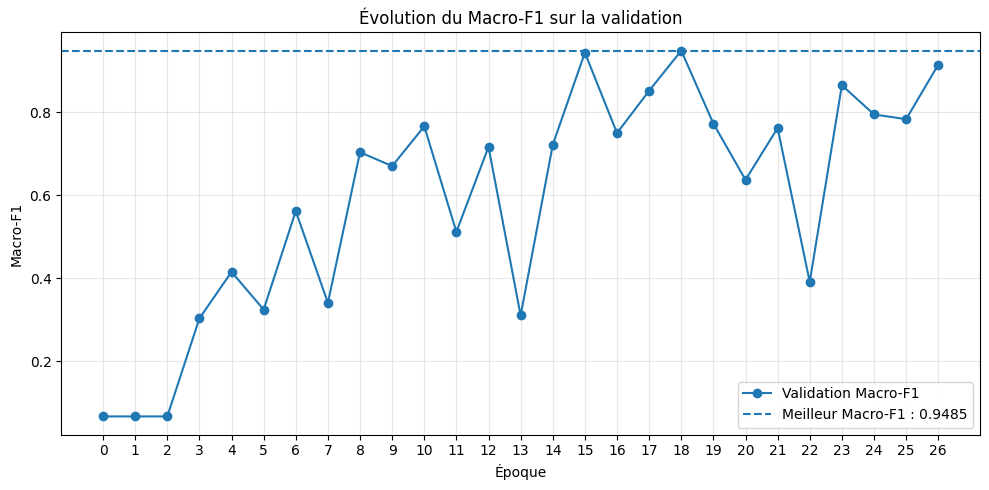

In [50]:
# Lecture du journal d'entraînement et visualisation de l'évolution du Macro-F1 sur la validation.

import pandas as pd
import matplotlib.pyplot as plt

history_df = pd.read_csv(
    os.path.join(OUTPUT_DIR, "training_log.csv")
)

print("Colonnes disponibles :", history_df.columns.tolist())

plt.figure(figsize=(10, 5))
plt.plot(
    history_df["val_macro_f1"],
    marker="o",
    label="Validation Macro-F1"
)

plt.axhline(
    y=macro_f1_callback.best_f1,
    linestyle="--",
    label=f"Meilleur Macro-F1 : {macro_f1_callback.best_f1:.4f}"
)

plt.title("Évolution du Macro-F1 sur la validation")
plt.xlabel("Époque")
plt.ylabel("Macro-F1")
plt.xticks(range(len(history_df)))
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [51]:
# Extraction des meilleures performances de validation depuis le journal d'entraînement.

best_epoch = history_df["val_macro_f1"].idxmax()
best_row = history_df.loc[best_epoch]

print("Meilleure époque :", best_epoch + 1)
print("Macro-F1 validation :", round(best_row["val_macro_f1"], 4))
print("Accuracy validation :", round(best_row["val_accuracy"], 4))
print("Loss validation :", round(best_row["val_loss"], 4))
print("\nNombre d'époques effectuées :", len(history_df))

Meilleure époque : 19
Macro-F1 validation : 0.9485
Accuracy validation : 0.9495
Loss validation : 0.1444

Nombre d'époques effectuées : 27


In [52]:
# Vérification de la sauvegarde des meilleurs poids et export du modèle E0 sélectionné au format Keras.

import json
import os

weights_path = os.path.join(OUTPUT_DIR, "best_e0.weights.h5")
model_path = os.path.join(OUTPUT_DIR, "best_e0.keras")

assert os.path.exists(weights_path), "Fichier des meilleurs poids introuvable."

model.save(model_path)

config = {
    "model": "CNN_E0",
    "input_shape": [224, 224, 3],
    "classes": CLASS_NAMES,
    "num_classes": NUM_CLASSES,
    "optimizer": "Adam",
    "learning_rate": 0.001,
    "batch_size": BATCH_SIZE,
    "max_epochs": 50,
    "epochs_completed": len(history_df),
    "best_epoch": int(best_epoch + 1),
    "best_val_macro_f1": float(best_row["val_macro_f1"]),
    "best_val_accuracy": float(best_row["val_accuracy"]),
    "best_val_loss": float(best_row["val_loss"]),
    "seed": SEED
}

with open(os.path.join(OUTPUT_DIR, "e0_config.json"), "w") as f:
    json.dump(config, f, indent=4)

print("Modèle sauvegardé :", model_path)
print("Poids sauvegardés :", weights_path)
print("Configuration sauvegardée.")
print("Fichiers :", os.listdir(OUTPUT_DIR))

Modèle sauvegardé : /content/e0_results/best_e0.keras
Poids sauvegardés : /content/e0_results/best_e0.weights.h5
Configuration sauvegardée.
Fichiers : ['best_e0.weights.h5', 'best_e0_model.keras', 'e0_config.json', 'training_log.csv', 'best_e0.keras']


In [53]:
# Chargement du meilleur modèle E0 et génération des prédictions sur le jeu de test interne.

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

model = tf.keras.models.load_model(model_path)

y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print("Nombre d'images évaluées :", len(y_true))
print("Nombre de prédictions :", len(y_pred))

23/23 ━━━━━━━━━━━━━━━━━━━━ 5s 193ms/step
Nombre d'images évaluées : 720
Nombre de prédictions : 720


In [54]:
# Calcul des performances du modèle sur le test interne avec l'Accuracy, le Macro-F1 et les métriques par classe.

test_accuracy = accuracy_score(y_true, y_pred)
test_macro_f1 = f1_score(y_true, y_pred, average="macro")

print("Accuracy test :", round(test_accuracy, 4))
print("Macro-F1 test :", round(test_macro_f1, 4))

print("\nRapport de classification :")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0
))

Accuracy test : 0.9528
Macro-F1 test : 0.9521

Rapport de classification :
                      precision    recall  f1-score   support

alternariose_precoce     0.9333    0.9459    0.9396       148
       cladosporiose     0.9774    0.9286    0.9524       140
      mildiou_tardif     0.9462    0.9044    0.9248       136
               saine     0.9737    1.0000    0.9867       148
          septoriose     0.9355    0.9797    0.9571       148

            accuracy                         0.9528       720
           macro avg     0.9532    0.9517    0.9521       720
        weighted avg     0.9531    0.9528    0.9526       720



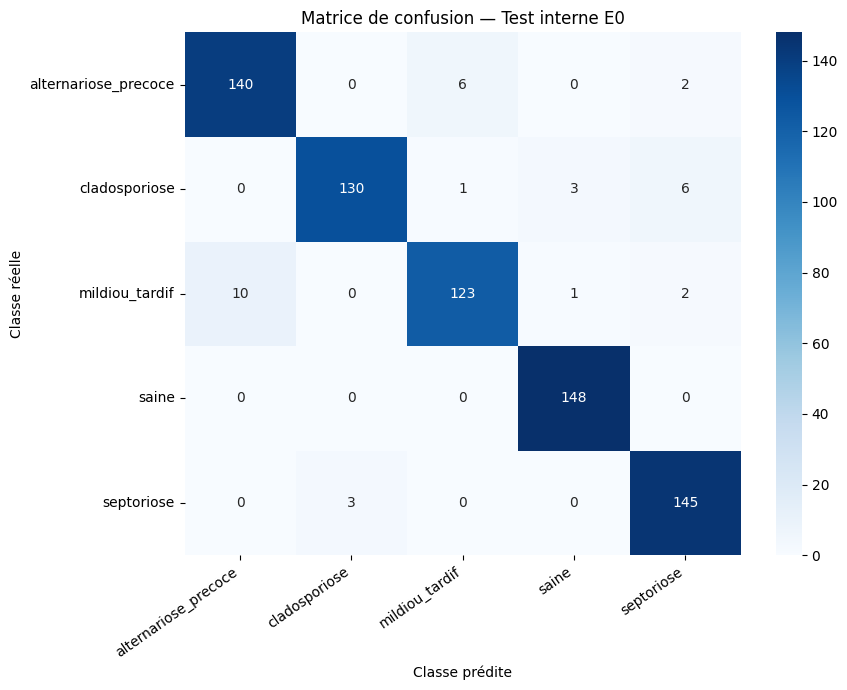

In [56]:
# Calcul et visualisation de la matrice de confusion pour analyser les erreurs de classification entre les cinq classes.
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES))
)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.title("Matrice de confusion — Test interne E0")
plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [57]:
# Affichage de la matrice de confusion sous forme de tableau numérique avec les noms des classes.

cm_df = pd.DataFrame(
    cm,
    index=[f"Réel : {name}" for name in CLASS_NAMES],
    columns=[f"Prédit : {name}" for name in CLASS_NAMES]
)

print(cm_df.to_string())

                             Prédit : alternariose_precoce  Prédit : cladosporiose  Prédit : mildiou_tardif  Prédit : saine  Prédit : septoriose
Réel : alternariose_precoce                            140                       0                        6               0                    2
Réel : cladosporiose                                     0                     130                        1               3                    6
Réel : mildiou_tardif                                   10                       0                      123               1                    2
Réel : saine                                             0                       0                        0             148                    0
Réel : septoriose                                        0                       3                        0               0                  145


In [58]:
# Sauvegarde des courbes de performance (Loss, Accuracy, et Macro-F1) sous forme d'images PNG dans le dossier de résultats.
import os
import matplotlib.pyplot as plt

# 1. Sauvegarde des courbes de Loss et Accuracy
fig1 = plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Train")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Évolution de la Loss")
plt.xlabel("Époque")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Train")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Évolution de l'Accuracy")
plt.xlabel("Époque")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
loss_acc_path = os.path.join(OUTPUT_DIR, "e0_loss_accuracy.png")
plt.savefig(loss_acc_path, dpi=300)
plt.close(fig1)
print("Graphique Loss/Accuracy sauvegardé dans :", loss_acc_path)

# 2. Sauvegarde de la courbe du Macro-F1 de validation
fig2 = plt.figure(figsize=(10, 5))
plt.plot(
    history_df["val_macro_f1"],
    marker="o",
    label="Validation Macro-F1",
    color="orange"
)

plt.axhline(
    y=macro_f1_callback.best_f1,
    linestyle="--",
    color="red",
    label=f"Meilleur Macro-F1 : {macro_f1_callback.best_f1:.4f}"
)

plt.title("Évolution du Macro-F1 sur la validation")
plt.xlabel("Époque")
plt.ylabel("Macro-F1")
plt.xticks(range(len(history_df)))
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

macro_f1_path = os.path.join(OUTPUT_DIR, "e0_macro_f1.png")
plt.savefig(macro_f1_path, dpi=300)
plt.close(fig2)
print("Graphique Macro-F1 de validation sauvegardé dans :", macro_f1_path)

# Affichage de la liste mise à jour des fichiers présents dans le répertoire de résultats
print("\nContenu final du dossier de résultats :", os.listdir(OUTPUT_DIR))

Graphique Loss/Accuracy sauvegardé dans : /content/e0_results/e0_loss_accuracy.png
Graphique Macro-F1 de validation sauvegardé dans : /content/e0_results/e0_macro_f1.png

Contenu final du dossier de résultats : ['best_e0.weights.h5', 'best_e0_model.keras', 'e0_macro_f1.png', 'e0_config.json', 'training_log.csv', 'best_e0.keras', 'e0_loss_accuracy.png']


In [59]:
# Regroupement des résultats expérimentaux E0 dans une archive ZIP.
import shutil
import os

OUTPUT_DIR = "/content/e0_results"
ZIP_PATH = "/content/PFA_E0_CNN_Baseline_Results"

archive_path = shutil.make_archive(
    ZIP_PATH,
    "zip",
    OUTPUT_DIR
)

print("Archive créée :", archive_path)
print("Taille :", round(os.path.getsize(archive_path) / (1024 * 1024), 2), "Mo")

print("\nFichiers inclus :")
for filename in sorted(os.listdir(OUTPUT_DIR)):
    print("-", filename)

Archive créée : /content/PFA_E0_CNN_Baseline_Results.zip
Taille : 3.91 Mo

Fichiers inclus :
- best_e0.keras
- best_e0.weights.h5
- best_e0_model.keras
- e0_config.json
- e0_loss_accuracy.png
- e0_macro_f1.png
- training_log.csv


In [60]:
# Téléchargement de l'archive des résultats E0 vers l'ordinateur.
from google.colab import files

files.download("/content/PFA_E0_CNN_Baseline_Results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>